In [9]:
!pip install matplotlib

ERROR: Could not find a version that satisfies the requirement matplotlib.pyplot (from versions: none)
ERROR: No matching distribution found for matplotlib.pyplot


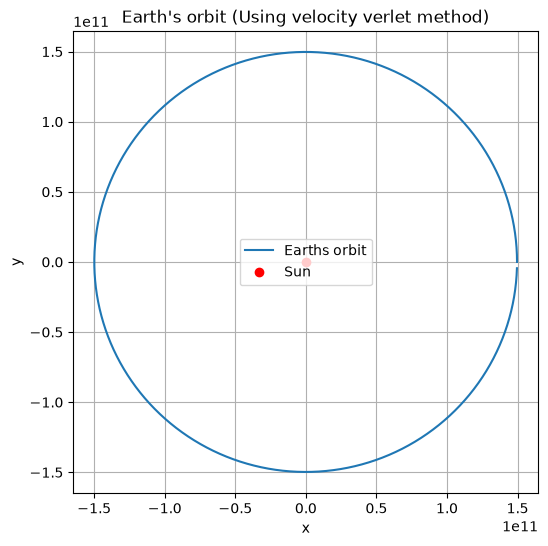

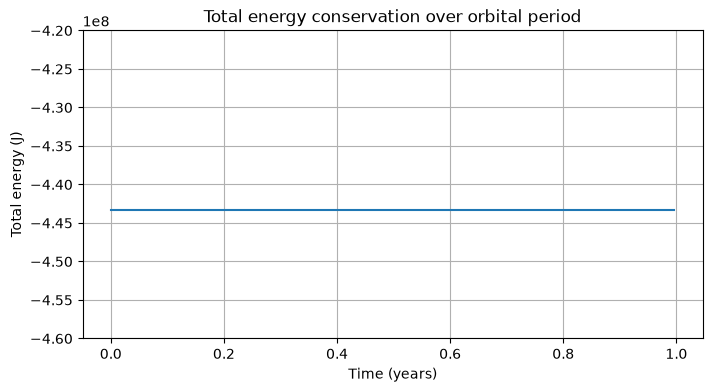

In [17]:
import numpy as np
import matplotlib.pyplot as plt

G = 6.67348e-11
Mass_sun = 1.989e30
R_orbit = 149.6e9

r0 = np.array([R_orbit, 0.0])
v0 = np.array([0.0, 29800.0])

def acceleration(r):
    x = r[0]
    y = r[1]

    r_abs = (x**2 + y**2) ** 0.5
    ax = -G * Mass_sun * x / (r_abs**3)
    ay = -G * Mass_sun * y / (r_abs**3)

    return np.array([ax, ay])

dt = 86400
steps = int((366 * 24 * 3600) / dt)

r = np.array(r0)
v  = np.array(v0)

r_orbit = []
energy = []
t = []

def total_energy(pos_vec, vel_vec, mass=1.0):
    
    T = 0.5 * mass * (vel_vec[0]**2 + vel_vec[1]**2)
    r_abs = (pos_vec[0]**2 + pos_vec[1]**2)**0.5
    V = -G * Mass_sun * mass / r_abs
    
    return T + V

for step in range(steps):
    r_orbit.append(r)
    energy.append(total_energy(r, v))
    t.append(step * dt)

    a = acceleration(r)
    r_update = r + v * dt + 0.5 * a * (dt**2)
    a_update = acceleration(r_update)
    v_update = v + 0.5 * (a + a_update) * dt 

    r = r_update 
    v = v_update 

r_orbit = np.array(r_orbit)
    
plt.figure(figsize=(6, 6))
plt.plot(r_orbit[:, 0], r_orbit[:, 1], label='Earths orbit')
plt.plot(0, 0, "ro", label='Sun')
plt.title("Earth's orbit (Using velocity verlet method)")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show 

print()

plt.figure(figsize=(8, 4))
plt.plot(np.array(t) / (365.25 * 24 * 3600), energy)
plt.title('Total energy conservation over orbital period')
plt.xlabel('Time (years)')
plt.ylabel('Total energy (J)')
plt.grid(True)
plt.ylim(-4.6e8, -4.2e8)
plt.show()
